**Student Name:** Shelia Howard  
**Course:** DSC640-T302 Data Presentation & Visualization (2267-1)  
**Assignment:** Term Project - Milestone 5  
**Due Date:** 08/23/2026  
**Dataset(s):** `nationaldatabaseofchildcareprices.xlsx` 

**Project Story:** Childcare Affordability as a Workforce Participation Barrier  
**Call to Action:** Approve the design and county screening phase of a targeted childcare affordability and employer partnership pilot for high-burden counties.

# DSC640 Term Project - Milestone 5

## Introduction

This final notebook consolidates the complete DSC640 term project into one submission. It reproduces the analysis of the National Database of Childcare Prices, documents the data preparation and assumptions, presents the final versions of three communication mediums, and includes the final project paper. The three mediums are a five-slide executive presentation, a county screening dashboard, and a one-page public infographic. Each medium uses the same verified evidence but adjusts the amount of detail, wording, and call to action for its intended audience.

The explanatory story treats childcare affordability as a workforce development concern rather than only a private household expense. The analysis does not claim that childcare prices independently cause workforce outcomes. Instead, it uses affordability burden and workforce measures as transparent screening information for a proposed local pilot.

Throughout the notebook, each code block includes comments explaining what the code is doing and why the step matters.

## Business Problem, Audience, and Purpose

**Business problem:** County policymakers and workforce development leaders need a defensible way to identify where childcare prices may place the greatest pressure on working families and complicate workforce participation.

**Primary audience:** County policymakers, workforce development board members, and local economic development leaders. They are comfortable with budgets and program decisions but may not know the childcare-price variables in the source dataset.

**Audience needs and likely resistance:** The audience needs a short decision path, county-level evidence, visible limitations, and a financially limited next step. Some members may view childcare as outside workforce development or resist a broad permanent program. The proposed pilot addresses that concern by asking first for design and screening, followed by local validation and evaluation before expansion.

**Purpose:** Make the requested decision clear at the beginning, show why targeted action is more appropriate than a uniform program, and provide a transparent screening framework that does not overstate causation.

## Import Libraries and Establish the Visual System

In [1]:
# Import Path so the notebook can test several safe locations for the assigned workbook.
from pathlib import Path

# Import warnings so nonessential rendering messages can be kept out of the final presentation.
import warnings

# Import NumPy for numeric calculations and missing-value handling.
import numpy as np

# Import pandas for reading, cleaning, reshaping, and summarizing the Excel dataset.
import pandas as pd

# Import Matplotlib for all original charts and final communication-medium visuals.
import matplotlib.pyplot as plt

# Import Matplotlib patches to build cards and callout boxes in the dashboard and infographic.
from matplotlib.patches import FancyBboxPatch

# Display charts directly below their code cells when the notebook is run.
%matplotlib inline

# Suppress nonessential warnings so the final notebook remains focused on the story.
warnings.filterwarnings("ignore")

# Set a consistent sans-serif font that is readable in notebooks and PDF exports.
plt.rcParams["font.family"] = "DejaVu Sans"

# Set a high default display resolution so labels remain sharp when exported.
plt.rcParams["figure.dpi"] = 130

# Define the shared color system used across all three communication mediums.
NAVY = "#17324D"

# Define teal as the main evidence color for affordability results.
TEAL = "#1D9A8A"

# Define gold as the action color used for the pilot recommendation.
GOLD = "#F2C14E"

# Define coral as the warning color for unusually high burdens.
CORAL = "#C85C41"

# Define light gray for backgrounds and low-emphasis structural elements.
LIGHT = "#F3F6F8"

# Define medium gray for supporting notes that should remain visible but secondary.
GRAY = "#617181"

### Explanation of Code Section 1

This block imports the analysis and visualization libraries and defines one coordinated visual system. Navy identifies policy content, teal represents evidence, gold highlights the requested action, and coral is reserved for unusually high burden. Reusing these colors, fonts, and emphasis rules across the presentation, dashboard, and infographic creates consistency and reduces cognitive load.

## Load and Validate the Assigned Dataset

In [2]:
# Identify the assigned workbook submitted with this notebook.
dataset_path = Path("nationaldatabaseofchildcareprices.xlsx")

# Stop with a clear message if the assigned workbook is unavailable.
if not dataset_path.exists():
    raise FileNotFoundError(
        "Place nationaldatabaseofchildcareprices.xlsx in the same folder as this notebook."
    )

# Read the assigned Excel worksheet into a pandas DataFrame for analysis.
raw = pd.read_excel(dataset_path, sheet_name="nationaldatabaseofchildcare")

# Define the exact fields needed for the final story so the analysis remains focused and auditable.
required_columns = [
    "State_Name", "State_Abbreviation", "County_Name", "County_FIPS_Code", "StudyYear",
    "MHI", "FLFPR_20to64_Under6", "PR_P", "UNR_16",
    "MCInfant", "MCInfant_flag", "MCToddler", "MCPreschool",
    "MFCCInfant", "MFCCToddler", "MFCCPreschool",
]

# Identify required fields that are absent so a changed or incorrect workbook fails transparently.
missing_columns = [column for column in required_columns if column not in raw.columns]

# Confirm that every required field is present before any metrics are calculated.
assert not missing_columns, f"Missing required columns: {missing_columns}"

# Display a compact validation summary instead of printing thousands of source rows.
pd.DataFrame({
    "Validation item": ["Source file", "Rows", "Columns", "Study years", "County FIPS values"],
    "Result": [
        dataset_path.name,
        f"{raw.shape[0]:,}",
        f"{raw.shape[1]:,}",
        f"{int(raw['StudyYear'].min())}-{int(raw['StudyYear'].max())}",
        f"{raw['County_FIPS_Code'].nunique():,}",
    ],
})

,Validation item,Result
0,Source file,nationaldatabaseofchildcareprices.xlsx
1,Rows,"34,567"
2,Columns,227
3,Study years,2008-2018
4,County FIPS values,"3,144"


### Explanation of Code Section 2

The assigned workbook is loaded from a portable list of possible locations and checked for all fields required by the story. The compact output confirms the expected size, time range, and county coverage without allowing a long data preview to overwhelm the final submission. This validation matters because a missing or renamed field could otherwise produce misleading results.

## Prepare the 2018 Analysis File and Calculate Affordability Burden

In [3]:
# Filter to 2018 because it is the most recent study year in the assigned 2008-2018 dataset.
analysis = raw.loc[raw["StudyYear"].eq(2018), required_columns].copy()

# Convert the county FIPS code to a five-character identifier so leading zeros are preserved conceptually.
analysis["County_FIPS"] = analysis["County_FIPS_Code"].astype("Int64").astype(str).str.zfill(5)

# Create a concise county-state label for charts and tables.
analysis["County_Label"] = (
    analysis["County_Name"].str.replace(" County", "", regex=False)
    + ", "
    + analysis["State_Abbreviation"]
)

# Map readable care-category names to their source weekly-price fields.
care_columns = {
    "Center infant": "MCInfant",
    "Center toddler": "MCToddler",
    "Center preschool": "MCPreschool",
    "Family infant": "MFCCInfant",
    "Family toddler": "MFCCToddler",
    "Family preschool": "MFCCPreschool",
}

# Calculate annualized price and affordability burden for each care category using 52 paid weeks.
for label, price_column in care_columns.items():
    # Create a stable code-friendly prefix from the readable category label.
    metric_prefix = label.lower().replace(" ", "_")
    # Annualize the weekly source price without modifying the original weekly field.
    analysis[f"{metric_prefix}_annual"] = analysis[price_column] * 52
    # Divide annualized price by county median household income and convert the ratio to a percentage.
    analysis[f"{metric_prefix}_burden"] = (
        analysis[f"{metric_prefix}_annual"] / analysis["MHI"] * 100
    )

# Replace infinite values with missing values in case a denominator is absent or invalid.
analysis = analysis.replace([np.inf, -np.inf], np.nan)

# Give the main center-infant affordability metric a shorter name for later visuals.
analysis["Burden"] = analysis["center_infant_burden"]

# Count usable center-infant records after the burden calculation.
usable_counties = int(analysis["Burden"].notna().sum())

# Calculate the project-defined 90th-percentile screening threshold from usable counties.
screening_threshold = float(analysis["Burden"].quantile(0.90))

# Confirm that missing prices remain missing instead of being silently treated as zero.
assert analysis.loc[analysis["MCInfant"].isna(), "Burden"].isna().all()

# Display a concise transformation audit for ethical transparency.
pd.DataFrame({
    "Transformation": [
        "Study-year filter",
        "Weekly-to-annual conversion",
        "Affordability formula",
        "Missing-price treatment",
        "Screening threshold",
    ],
    "Applied rule": [
        "Retained 2018 only",
        "Weekly price multiplied by 52",
        "Annualized price divided by county median household income",
        "Retained as missing; never replaced with zero",
        "90th percentile of usable center-infant burden values",
    ],
})

,Transformation,Applied rule
0,Study-year filter,Retained 2018 only
1,Weekly-to-annual conversion,Weekly price multiplied by 52
2,Affordability formula,Annualized price divided by county median hous...
3,Missing-price treatment,Retained as missing; never replaced with zero
4,Screening threshold,90th percentile of usable center-infant burden...


### Explanation of Code Section 3

This block creates the analytical measures used throughout all three mediums. Weekly childcare prices are annualized using 52 paid weeks and divided by county median household income. The result is an affordability-burden percentage, not the actual share paid by every family. Missing prices remain missing. The 90th percentile is a project-defined screening threshold for review, not an official affordability standard or automatic eligibility rule.

## Verify Key Findings and Data-Quality Conditions

In [4]:
# Build one summary row per care category using only nonmissing burden values.
care_summary_rows = []

# Loop through each readable category and its original weekly-price field.
for label, price_column in care_columns.items():
    # Recreate the metric prefix used when the burden fields were calculated.
    metric_prefix = label.lower().replace(" ", "_")
    # Store the burden series for concise calculations.
    burden_series = analysis[f"{metric_prefix}_burden"]
    # Append verified counts and medians to the summary list.
    care_summary_rows.append({
        "Care category": label,
        "Usable counties": int(burden_series.notna().sum()),
        "Median weekly price": float(analysis.loc[burden_series.notna(), price_column].median()),
        "Median burden (%)": float(burden_series.median()),
        "90th percentile (%)": float(burden_series.quantile(0.90)),
    })

# Convert the accumulated category summaries into a readable table.
care_summary = pd.DataFrame(care_summary_rows)

# Sort counties from highest to lowest center-infant affordability burden.
top_counties = analysis.loc[
    analysis["Burden"].notna(),
    ["County_Label", "Burden", "FLFPR_20to64_Under6", "PR_P", "UNR_16", "MCInfant_flag"],
].sort_values("Burden", ascending=False)

# Preserve the source flag codes without assigning unsupported meanings.
top_counties["Price quality note"] = top_counties["MCInfant_flag"].map(
    lambda value: (
        f"Source imputation flag {int(value)}"
        if pd.notna(value)
        else "Flag unavailable"
    )
)

# Create a presentation-ready copy without changing the numeric analysis table.
care_summary_display = care_summary.copy()

# Round weekly prices to cents for readable validation output.
care_summary_display["Median weekly price"] = care_summary_display["Median weekly price"].round(2)

# Round burden measures to one decimal place to match the explanatory visuals.
care_summary_display[["Median burden (%)", "90th percentile (%)"]] = care_summary_display[["Median burden (%)", "90th percentile (%)"]].round(1)

# Display the verified category summary as the final expression in the cell.
care_summary_display

,Care category,Usable counties,Median weekly price,Median burden (%),90th percentile (%)
0,Center infant,2360,153.60,16.1,21.3
1,Center toddler,2360,140.00,14.5,19.0
2,Center preschool,2360,125.00,13.5,17.8
3,Family infant,2348,120.00,12.5,16.6
4,Family toddler,2348,113.04,11.9,15.6
5,Family preschool,2348,110.00,11.7,15.1


### Explanation of Code Section 4

The summary verifies that center-based infant care has the highest median burden among the six selected categories, which justifies using it as the first screening lens. The code also preserves the source price flag and creates readable quality notes. These flags are important because many childcare-price values were estimated or imputed; county prioritization should therefore be followed by local verification.

The source imputation flags are retained as provided. The numeric codes are not treated as quality rankings. Their exact meanings should be interpreted using the technical guide before a county is selected for action.

## Final Medium 1: Executive Presentation

The executive presentation is designed for policymakers and workforce leaders who need a concise decision sequence. The five slides move from the requested decision to burden evidence, geographic concentration, workforce context, and a limited pilot action plan. Original charts appear directly in the presentation, addressing the professor's Milestone 2 feedback.

### Executive Slide 1: Recommendation and Headline Metrics

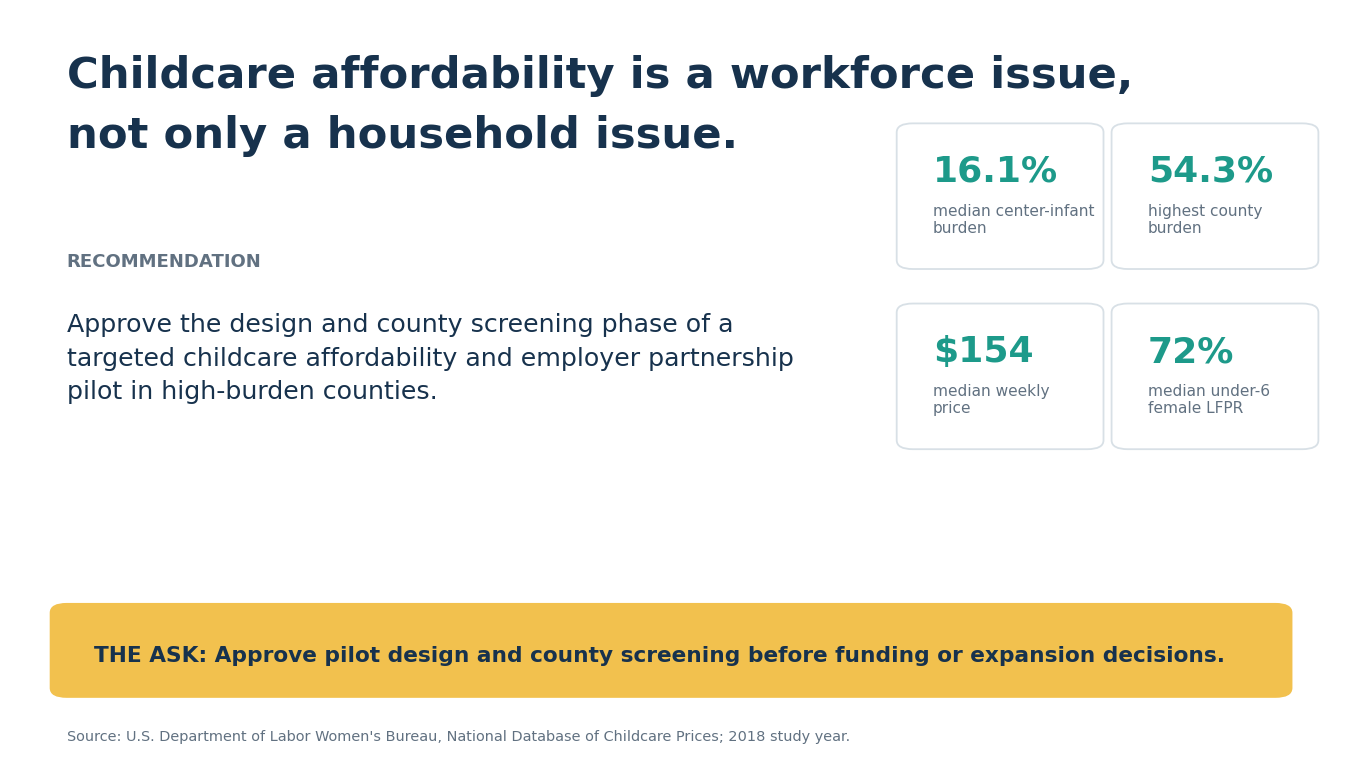

In [5]:
# Calculate the four verified headline metrics for the opening slide.
headline_metrics = [
    (
        f"{analysis['Burden'].median():.1f}%",
        "median center-infant\nburden",
    ),
    (
        f"{analysis['Burden'].max():.1f}%",
        "highest county\nburden",
    ),
    (
        f"${analysis.loc[analysis['Burden'].notna(), 'MCInfant'].median():.0f}",
        "median weekly\nprice",
    ),
    (
        f"{analysis.loc[analysis['Burden'].notna(), 'FLFPR_20to64_Under6'].median():.0f}%",
        "median under-6\nfemale LFPR",
    ),
]

# Create a widescreen figure that functions as executive presentation slide 1.
fig, ax = plt.subplots(figsize=(13.33, 7.5))

# Remove axes because this slide uses a presentation layout rather than a coordinate chart.
ax.axis("off")

# Add the decision-focused slide title in the shared policy color.
ax.text(0.04, 0.90, "Childcare affordability is a workforce issue,", fontsize=24, weight="bold", color=NAVY)

# Complete the title on a second line to preserve readable line length.
ax.text(0.04, 0.82, "not only a household issue.", fontsize=24, weight="bold", color=NAVY)

# State the recommendation immediately so the audience knows why the evidence matters.
ax.text(
    0.04,
    0.68,
    "RECOMMENDATION",
    fontsize=10,
    weight="bold",
    color=GRAY,
    va="top",
)

# Add the specific pilot recommendation using a controlled text width.
ax.text(
    0.04, 0.60,
    "Approve the design and county screening phase of a\n"
    "targeted childcare affordability and employer partnership\n"
    "pilot in high-burden counties.",
    fontsize=14, color=NAVY, linespacing=1.5, va="top",
)

# Position the four metric cards in a two-by-two grid on the right side.
for index, (value, label) in enumerate(headline_metrics):
    # Calculate the horizontal card position from the item index.
    card_x = 0.67 + (index % 2) * 0.16
    # Calculate the vertical card position from the item index.
    card_y = 0.67 - (index // 2) * 0.24
    # Draw a rounded white card with a subtle border.
    card = FancyBboxPatch((card_x, card_y), 0.13, 0.17, boxstyle="round,pad=0.012", facecolor="white", edgecolor="#D8E0E6")
    # Add the card to the slide.
    ax.add_patch(card)
    # Display the headline number in the main evidence color.
    ax.text(card_x + 0.015, card_y + 0.105, value, fontsize=20, weight="bold", color=TEAL)
    # Display the short metric definition under the number.
    ax.text(card_x + 0.015, card_y + 0.04, label, fontsize=8.5, color=GRAY, wrap=True)

# Add a gold action banner that reinforces the limited nature of the ask.
ax.add_patch(FancyBboxPatch((0.04, 0.10), 0.90, 0.10, boxstyle="round,pad=0.012", facecolor=GOLD, edgecolor=GOLD))

# State the requested action in the action banner.
ax.text(0.06, 0.135, "THE ASK: Approve pilot design and county screening before funding or expansion decisions.", fontsize=12, weight="bold", color=NAVY)

# Add a transparent source and scope note at the bottom.
ax.text(0.04, 0.03, "Source: U.S. Department of Labor Women's Bureau, National Database of Childcare Prices; 2018 study year.", fontsize=8, color=GRAY)

# Display the completed first executive slide.
plt.show()

### Executive Slide 1 Interpretation

The opening places the decision before the detail. Four metrics establish magnitude and scope without requiring the audience to decode a technical chart. The gold banner makes the call to action unmistakable while limiting the request to pilot design and screening rather than immediate large-scale funding.

### Executive Slide 2: Compare Childcare Burden by Care Category

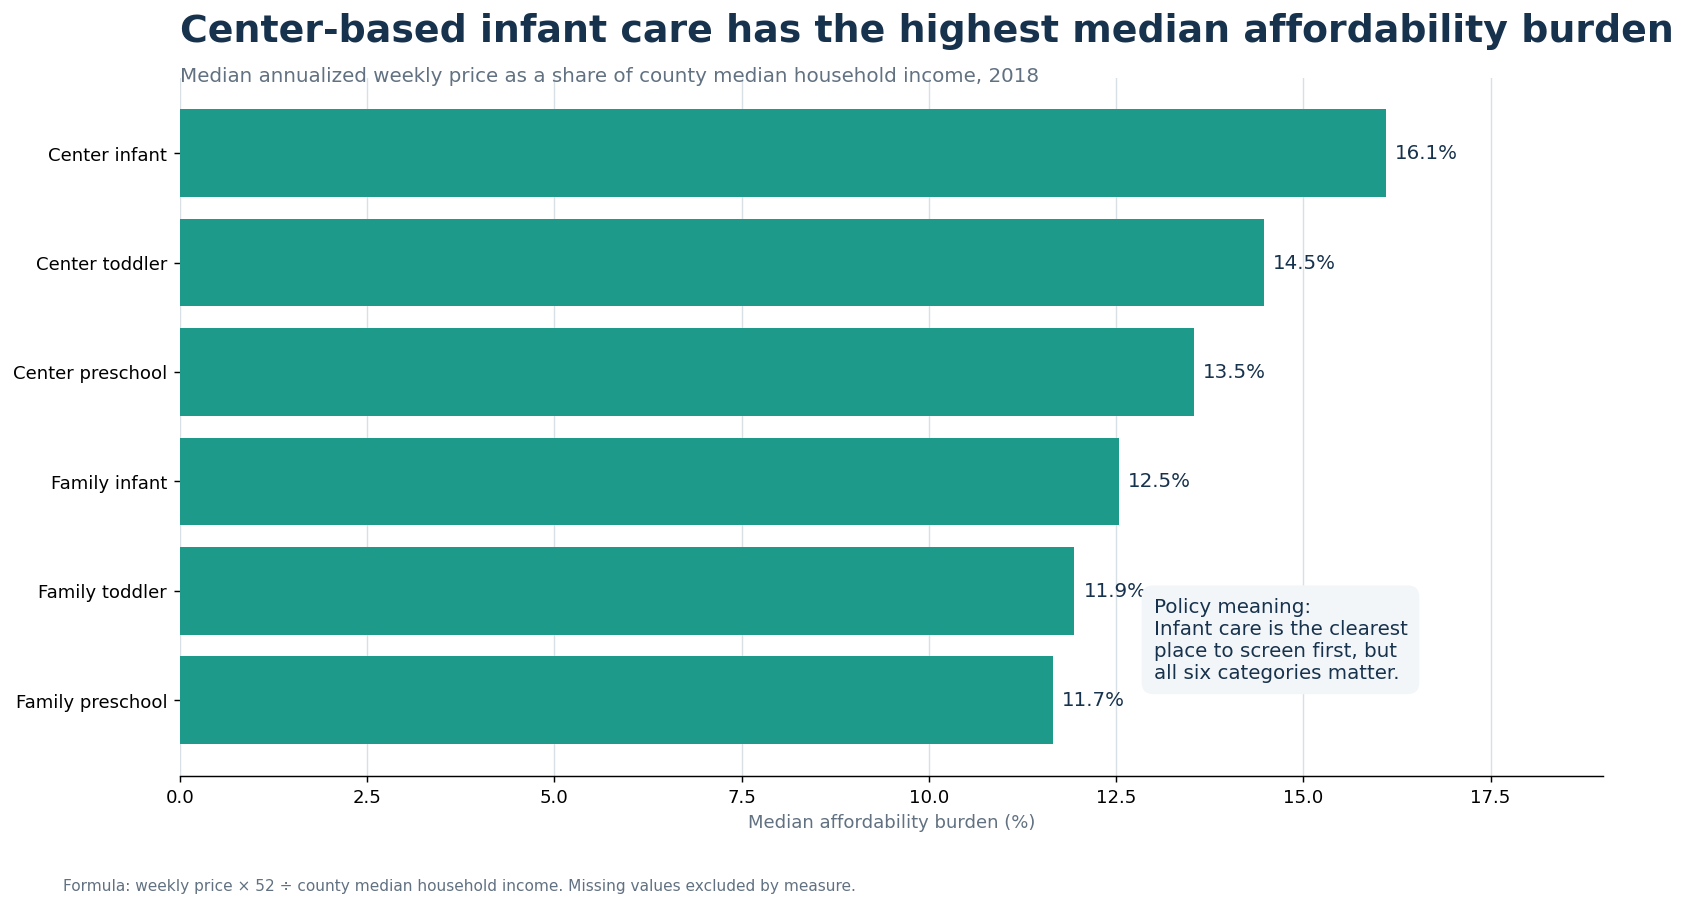

In [6]:
# Sort care categories by median burden so the highest-burden category appears first.
care_plot = care_summary.sort_values("Median burden (%)", ascending=True)

# Create executive presentation slide 2 with space for both chart and interpretation.
fig, ax = plt.subplots(figsize=(13.33, 7.5))

# Draw horizontal bars from a common zero baseline for accurate percentage comparison.
bars = ax.barh(care_plot["Care category"], care_plot["Median burden (%)"], color=TEAL)

# Label each bar directly so the audience does not have to estimate values from the axis.
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in care_plot["Median burden (%)"]], padding=5, color=NAVY, fontsize=11)

# State the chart takeaway in the title instead of using a generic topic label.
ax.set_title("Center-based infant care has the highest median affordability burden", loc="left", fontsize=21, weight="bold", color=NAVY, pad=20)

# Explain the denominator directly in the subtitle.
ax.text(0, 5.65, "Median annualized weekly price as a share of county median household income, 2018", fontsize=11, color=GRAY)

# Label the horizontal scale with its unit.
ax.set_xlabel("Median affordability burden (%)", color=GRAY)

# Remove the redundant vertical axis label.
ax.set_ylabel("")

# Extend the scale enough to prevent direct labels from clipping.
ax.set_xlim(0, 19)

# Keep only light horizontal reference structure and remove unnecessary borders.
ax.spines[["top", "right", "left"]].set_visible(False)

# Use subtle vertical gridlines behind the bars to support comparison.
ax.grid(axis="x", color="#D8E0E6", linewidth=0.8)

# Place gridlines behind the bars.
ax.set_axisbelow(True)

# Add the policy meaning as a concise callout inside the available chart area.
ax.text(13.0, 0.2, "Policy meaning:\nInfant care is the clearest\nplace to screen first, but\nall six categories matter.", fontsize=11, color=NAVY, bbox=dict(boxstyle="round,pad=0.6", facecolor=LIGHT, edgecolor="none"))

# Add the source and formula note required for ethical interpretation.
fig.text(0.08, 0.03, "Formula: weekly price × 52 ÷ county median household income. Missing values excluded by measure.", fontsize=8.5, color=GRAY)

# Use available canvas space efficiently without clipping the source note.
plt.tight_layout(rect=[0.04, 0.07, 0.98, 0.95])

# Display the completed second executive slide.
plt.show()

### Executive Slide 2 Interpretation

Directly labeled horizontal bars make the six care categories easy to compare. Center-based infant care has a median burden of 16.1%, compared with 14.5% for center toddler care and 13.5% for center preschool care. Family-care categories are lower but remain meaningful. The chart supports a clear screening priority without implying that only one care setting matters.

### Executive Slide 3: Identify Geographic Concentration

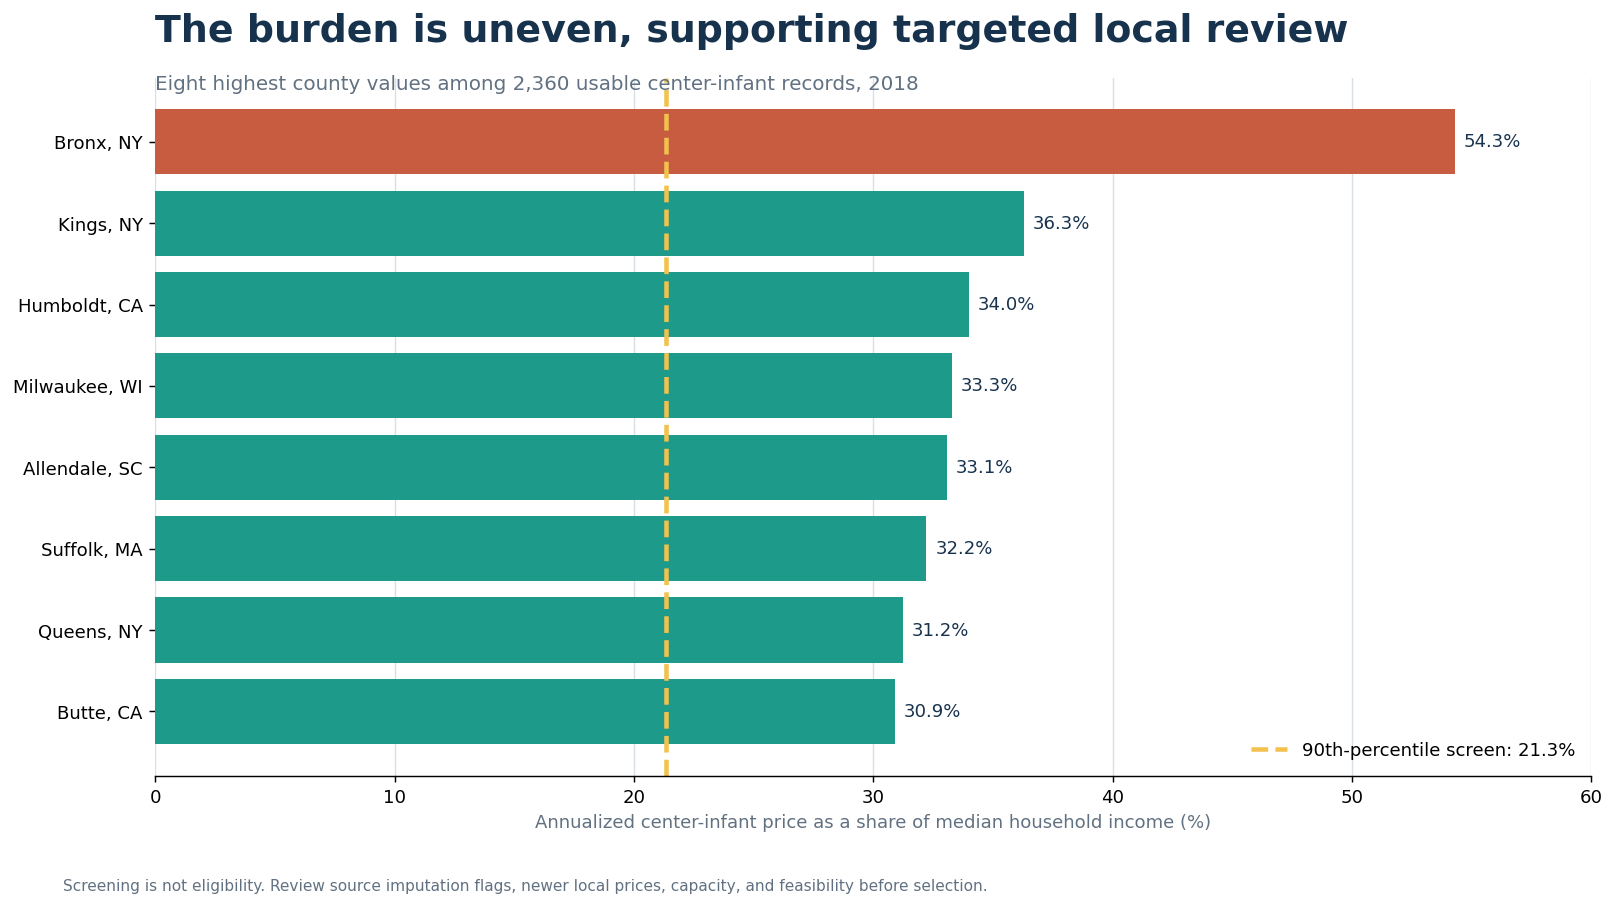

In [7]:
# Select the eight highest-burden counties for a focused geographic comparison.
top_eight = top_counties.head(8).sort_values("Burden", ascending=True)

# Create executive presentation slide 3 as a ranked bar chart.
fig, ax = plt.subplots(figsize=(13.33, 7.5))

# Color the highest value coral and the remaining high-burden counties teal.
bar_colors = [CORAL if value == top_eight["Burden"].max() else TEAL for value in top_eight["Burden"]]

# Draw horizontal bars to allow readable county labels.
bars = ax.barh(top_eight["County_Label"], top_eight["Burden"], color=bar_colors)

# Add exact percentages to each county bar.
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in top_eight["Burden"]], padding=5, fontsize=10, color=NAVY)

# Mark the screening threshold with a dashed reference line.
ax.axvline(screening_threshold, color=GOLD, linestyle="--", linewidth=2.5, label=f"90th-percentile screen: {screening_threshold:.1f}%")

# Use a conclusion-style title that explains the policy implication.
ax.set_title("The burden is uneven, supporting targeted local review", loc="left", fontsize=21, weight="bold", color=NAVY, pad=20)

# Clarify that the chart shows the highest county values.
ax.text(
    0,
    7.65,
    f"Eight highest county values among {usable_counties:,} usable "
    "center-infant records, 2018",
    fontsize=11,
    color=GRAY,
)

# Label the quantitative axis and remove the redundant category-axis label.
ax.set_xlabel("Annualized center-infant price as a share of median household income (%)", color=GRAY)

# Remove the redundant vertical axis label.
ax.set_ylabel("")

# Extend the scale so direct labels remain visible.
ax.set_xlim(0, 60)

# Remove unnecessary plot borders.
ax.spines[["top", "right", "left"]].set_visible(False)

# Add subtle gridlines behind the data.
ax.grid(axis="x", color="#D8E0E6", linewidth=0.8)

# Keep gridlines behind the bars.
ax.set_axisbelow(True)

# Show the screening threshold legend in a nonblocking location.
ax.legend(loc="lower right", frameon=False)

# Add a quality warning that prevents automatic county selection.
fig.text(0.08, 0.03, "Screening is not eligibility. Review source imputation flags, newer local prices, capacity, and feasibility before selection.", fontsize=8.5, color=GRAY)

# Preserve space for the source and warning note.
plt.tight_layout(rect=[0.04, 0.07, 0.98, 0.95])

# Display the completed third executive slide.
plt.show()

### Executive Slide 3 Interpretation

County burden varies sharply, from the 21.3% screening threshold to a maximum of 54.3%. This variation supports targeted review rather than a uniform program. The chart deliberately states that screening is not eligibility because the source includes imputed prices and county averages can hide within-county differences.

### Executive Slide 4: Add Workforce Context

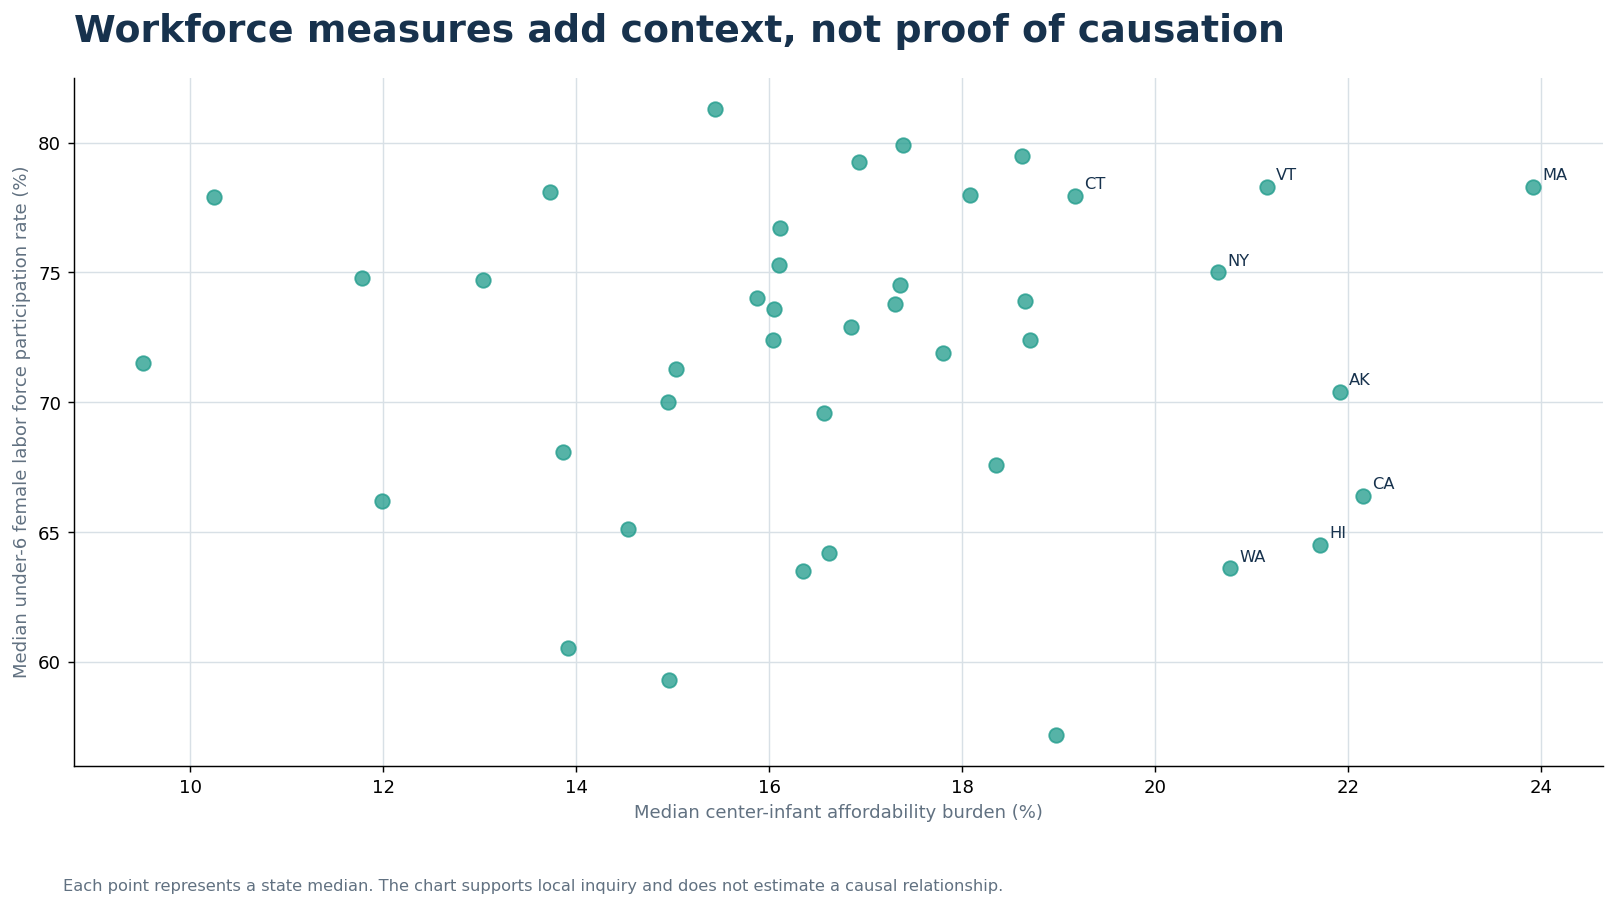

In [8]:
# Create one state-level point for affordability burden and workforce context.
state_context = (
    analysis.dropna(subset=["Burden", "FLFPR_20to64_Under6"])
    .groupby("State_Abbreviation", as_index=False)
    .agg(
        Median_Burden=("Burden", "median"),
        Median_LFPR=("FLFPR_20to64_Under6", "median"),
    )
)

# Identify the eight states with the highest median burden for labeling.
highlight_states = set(
    state_context.nlargest(8, "Median_Burden")["State_Abbreviation"]
)

# Create the workforce-context scatterplot.
fig, ax = plt.subplots(figsize=(13.33, 7.5))

# Plot all states using one consistent coordinate system.
ax.scatter(
    state_context["Median_Burden"],
    state_context["Median_LFPR"],
    color=TEAL,
    s=65,
    alpha=0.75,
)

# Label the selected high-burden states.
for _, row in state_context.iterrows():
    if row["State_Abbreviation"] in highlight_states:
        ax.annotate(
            row["State_Abbreviation"],
            (row["Median_Burden"], row["Median_LFPR"]),
            xytext=(5, 4),
            textcoords="offset points",
            fontsize=9,
            color=NAVY,
        )

# State the correct, noncausal interpretation.
ax.set_title(
    "Workforce measures add context, not proof of causation",
    loc="left",
    fontsize=21,
    weight="bold",
    color=NAVY,
    pad=20,
)

# Label both measures directly.
ax.set_xlabel("Median center-infant affordability burden (%)", color=GRAY)
ax.set_ylabel("Median under-6 female labor force participation rate (%)", color=GRAY)

# Add light reference gridlines.
ax.grid(color="#D8E0E6", linewidth=0.8)
ax.set_axisbelow(True)

# Remove unnecessary chart borders.
ax.spines[["top", "right"]].set_visible(False)

# Add the interpretation safeguard.
fig.text(
    0.08,
    0.03,
    "Each point represents a state median. The chart supports local inquiry "
    "and does not estimate a causal relationship.",
    fontsize=9,
    color=GRAY,
)

plt.tight_layout(rect=[0.04, 0.08, 0.98, 0.95])
plt.show()

### Executive Slide 4 Interpretation

The paired state medians demonstrate how workforce context can be shown without implying a statistical cause-and-effect relationship. High childcare burden may pressure household choices, but labor force participation also reflects wages, job availability, family structure, provider supply, transportation, and many other conditions. The visual is therefore a prompt for local inquiry, not a causal model.

### Executive Slide 5: Define the Pilot Decision

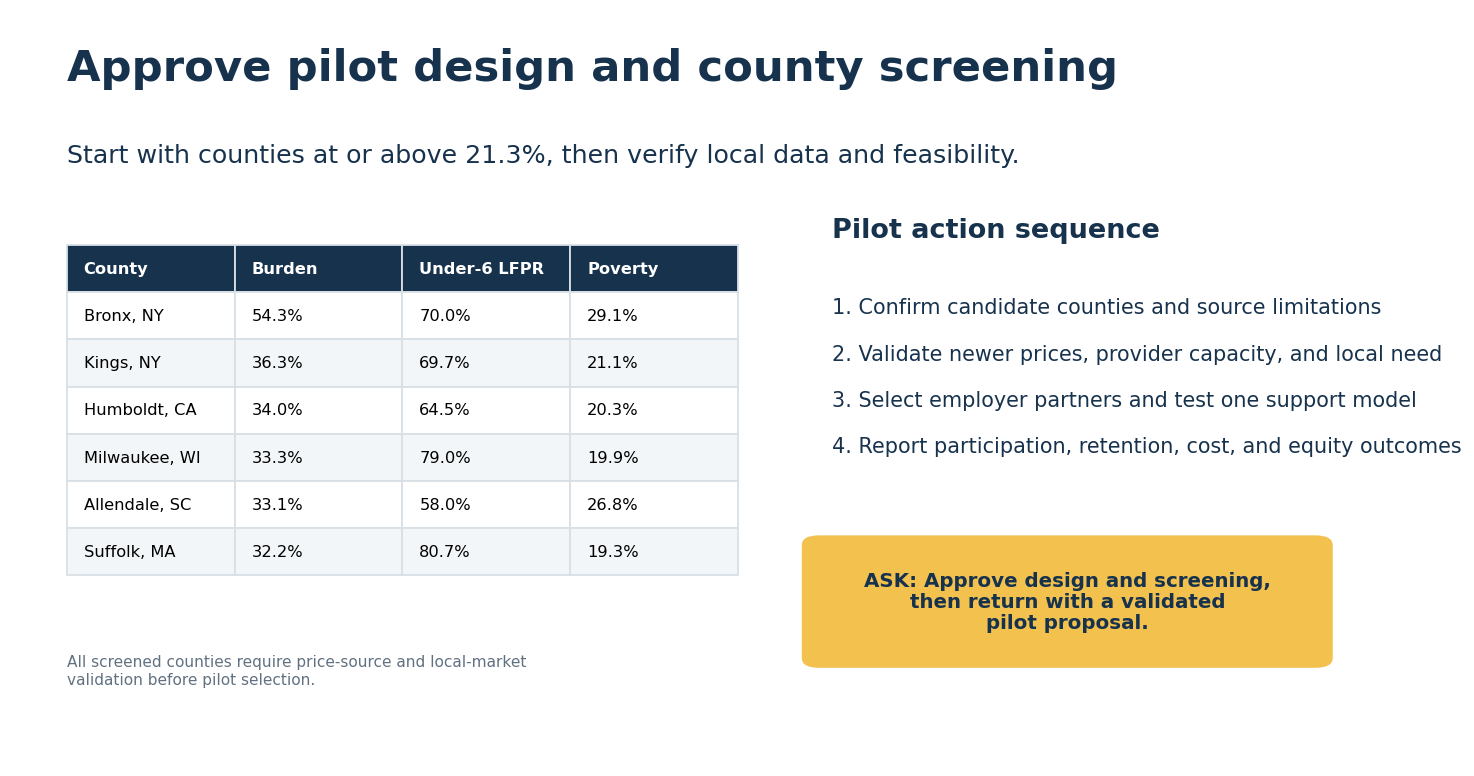

In [9]:
# Select six high-burden counties from the numeric analysis table.
pilot_table = top_counties.head(6)[
    [
        "County_Label",
        "Burden",
        "FLFPR_20to64_Under6",
        "PR_P",
    ]
].copy()

# Rename the source fields for the executive audience.
pilot_table.columns = [
    "County",
    "Burden",
    "Under-6 LFPR",
    "Poverty",
]

# Format burden as a percentage for display.
pilot_table["Burden"] = pilot_table["Burden"].map(
    lambda value: f"{value:.1f}%" if pd.notna(value) else "Missing"
)

# Format labor force participation as a percentage for display.
pilot_table["Under-6 LFPR"] = pilot_table["Under-6 LFPR"].map(
    lambda value: f"{value:.1f}%" if pd.notna(value) else "Missing"
)

# Format poverty as a percentage for display.
pilot_table["Poverty"] = pilot_table["Poverty"].map(
    lambda value: f"{value:.1f}%" if pd.notna(value) else "Missing"
)

# Create executive presentation slide 5 as a recommendation and action sequence.
fig, ax = plt.subplots(figsize=(13.33, 7.5))

# Remove axes because the final slide uses a decision layout with a table and action steps.
ax.axis("off")

# Add the final recommendation title.
ax.text(0.04, 0.91, "Approve pilot design and county screening", fontsize=24, weight="bold", color=NAVY)

# State the two-stage screening rule clearly.
ax.text(0.04, 0.80, f"Start with counties at or above {screening_threshold:.1f}%, then verify local data and feasibility.", fontsize=14, color=NAVY)

# Render the high-burden county table on the left side of the slide.
table = ax.table(cellText=pilot_table.values, colLabels=pilot_table.columns, cellLoc="left", colLoc="left", bbox=[0.04, 0.25, 0.50, 0.44])

# Set a readable, consistent table font size.
table.auto_set_font_size(False)

# Apply the chosen font size to all table cells.
table.set_fontsize(9)

# Style every table cell for clean executive reading.
for (row_index, column_index), cell in table.get_celld().items():
    # Use a navy header with white text.
    if row_index == 0:
        cell.set_facecolor(NAVY)
        cell.set_text_props(color="white", weight="bold")
    # Alternate light row shading in the table body.
    else:
        cell.set_facecolor("white" if row_index % 2 else LIGHT)
    # Use subtle cell borders that organize without dominating.
    cell.set_edgecolor("#D8E0E6")

# Add an action-sequence heading on the right side.
ax.text(0.61, 0.70, "Pilot action sequence", fontsize=15, weight="bold", color=NAVY)

# List the four concrete steps required before expansion.
ax.text(
    0.61, 0.62,
    "1. Confirm candidate counties and source limitations\n\n"
    "2. Validate newer prices, provider capacity, and local need\n\n"
    "3. Select employer partners and test one support model\n\n"
    "4. Report participation, retention, cost, and equity outcomes",
    fontsize=11.5, color=NAVY, va="top",
)

# Add the final gold call-to-action banner.
ax.add_patch(
    FancyBboxPatch(
        (0.60, 0.14),          # Left and bottom position
        0.37,                  # Box width
        0.15,                  # Box height
        boxstyle="round,pad=0.012",
        facecolor=GOLD,
        edgecolor=GOLD,
    )
)

# Center the full decision statement inside the yellow box.
ax.text(
    0.785,
    0.215,
    "ASK: Approve design and screening,\n"
    "then return with a validated\n"
    "pilot proposal.",
    fontsize=11,
    weight="bold",
    color=NAVY,
    ha="center",
    va="center",
    linespacing=1.15,
)

# Reinforce the validation requirement below the screening table.
ax.text(
    0.04,
    0.145,
    "All screened counties require price-source and local-market\n"
    "validation before pilot selection.",
    fontsize=8.5,
    color=GRAY,
    va="top",
    linespacing=1.3,
)

# Display the completed fifth executive slide.
plt.show()

### Executive Slide 5 Interpretation

The final slide converts the evidence into a controlled decision process. High burden starts the review, but local price validation, provider capacity, employer participation, and feasibility determine whether a county proceeds. The requested approval is intentionally limited to design and screening, after which leaders would receive a validated pilot proposal with outcomes and safeguards.

## Final Medium 2: County Screening Dashboard

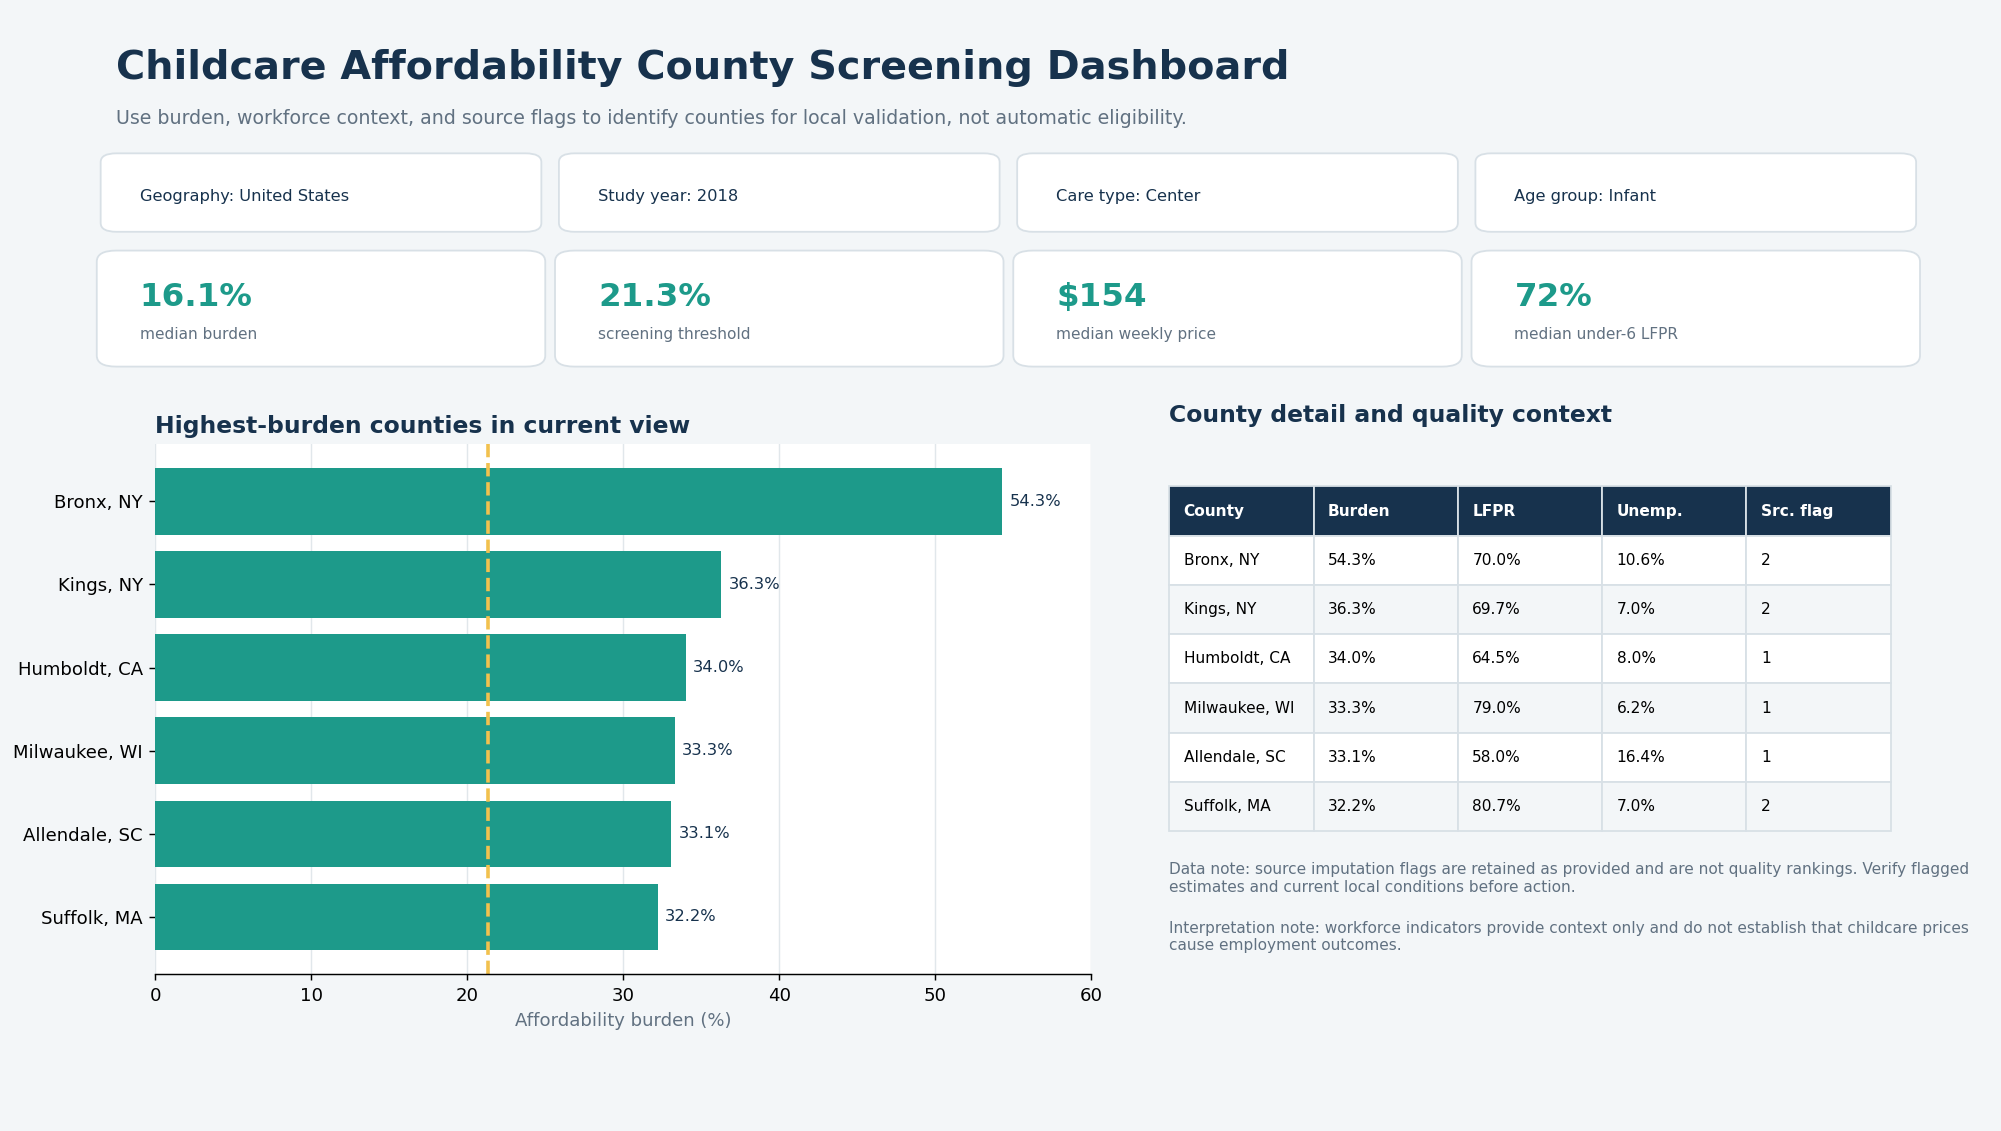

In [10]:
# Use the national 2018 center-infant view as the default dashboard state.
dashboard_counties = top_counties.head(6).copy()

# Create a wide dashboard canvas with a light neutral background.
fig = plt.figure(figsize=(15, 8.5), facecolor=LIGHT)

# Add a full-canvas invisible axis for the dashboard title, filters, and metric cards.
canvas = fig.add_axes([0, 0, 1, 1])

# Remove coordinate axes from the dashboard canvas.
canvas.axis("off")

# Add a direct dashboard title for policy analysts and workforce staff.
canvas.text(0.04, 0.94, "Childcare Affordability County Screening Dashboard", fontsize=22, weight="bold", color=NAVY)

# Explain the dashboard's specific decision-support purpose.
canvas.text(0.04, 0.90, "Use burden, workforce context, and source flags to identify counties for local validation, not automatic eligibility.", fontsize=10.5, color=GRAY)

# Define the active selections represented in the static dashboard view.
active_selections = [
    "Geography: United States",
    "Study year: 2018",
    "Care type: Center",
    "Age group: Infant",
]

# Draw and label the four active-selection cards.
for index, label in enumerate(active_selections):
    # Calculate the horizontal position for each selection card.
    selection_x = 0.04 + index * 0.235

    # Add the selection-card background and border.
    canvas.add_patch(
        FancyBboxPatch(
            (selection_x, 0.81),
            0.21,
            0.055,
            boxstyle="round,pad=0.008",
            facecolor="white",
            edgecolor="#D8E0E6",
        )
    )

    # Display the active selection inside its corresponding card.
    canvas.text(
        selection_x + 0.012,
        0.83,
        label,
        fontsize=9,
        color=NAVY,
    )

# Define the four dashboard headline metrics from the verified analysis.
dashboard_metrics = [
    (f"{analysis['Burden'].median():.1f}%", "median burden"),
    (f"{screening_threshold:.1f}%", "screening threshold"),
    (f"${analysis.loc[analysis['Burden'].notna(), 'MCInfant'].median():.0f}", "median weekly price"),
    (f"{analysis.loc[analysis['Burden'].notna(), 'FLFPR_20to64_Under6'].median():.0f}%", "median under-6 LFPR"),
]

# Draw the four headline cards below the filters.
for index, (value, label) in enumerate(dashboard_metrics):
    # Calculate each card's horizontal position.
    metric_x = 0.04 + index * 0.235
    # Add a white rounded metric card.
    canvas.add_patch(FancyBboxPatch((metric_x, 0.69), 0.21, 0.085, boxstyle="round,pad=0.010", facecolor="white", edgecolor="#D8E0E6"))
    # Display the metric value in teal.
    canvas.text(metric_x + 0.012, 0.735, value, fontsize=18, weight="bold", color=TEAL)
    # Display the metric definition under the value.
    canvas.text(metric_x + 0.012, 0.705, label, fontsize=8.5, color=GRAY)

# Add the dashboard's ranked county chart in the lower-left panel.
chart_ax = fig.add_axes([0.06, 0.13, 0.48, 0.48], facecolor="white")

# Sort the six displayed counties so the largest bar appears at the top.
dashboard_plot = dashboard_counties.sort_values("Burden", ascending=True)

# Draw the ranked bars using the shared evidence color.
chart_bars = chart_ax.barh(dashboard_plot["County_Label"], dashboard_plot["Burden"], color=TEAL)

# Label each county bar with its exact burden.
chart_ax.bar_label(chart_bars, labels=[f"{value:.1f}%" for value in dashboard_plot["Burden"]], padding=4, fontsize=9, color=NAVY)

# Mark the national screening threshold on the dashboard chart.
chart_ax.axvline(screening_threshold, color=GOLD, linestyle="--", linewidth=2)

# Add a functional chart title.
chart_ax.set_title("Highest-burden counties in current view", loc="left", fontsize=13, weight="bold", color=NAVY)

# Label the chart scale.
chart_ax.set_xlabel("Affordability burden (%)", color=GRAY)

# Remove unnecessary plot borders.
chart_ax.spines[["top", "right", "left"]].set_visible(False)

# Add light comparison gridlines.
chart_ax.grid(axis="x", color="#E1E7EB")

# Keep the gridlines behind the bars.
chart_ax.set_axisbelow(True)

# Extend the scale so direct labels do not clip.
chart_ax.set_xlim(0, 60)

# Add the detailed screening table in the lower-right panel.
table_ax = fig.add_axes([0.58, 0.13, 0.37, 0.48], facecolor="white")

# Remove table-panel axes.
table_ax.axis("off")

# Add a panel title that explains the table's purpose.
table_ax.set_title("County detail and quality context", loc="left", fontsize=13, weight="bold", color=NAVY, pad=12)

# Prepare the dashboard table with five decision-relevant fields.
dashboard_table = dashboard_counties[["County_Label", "Burden", "FLFPR_20to64_Under6", "UNR_16", "MCInfant_flag"]].copy()

# Rename the fields with compact audience-friendly labels.
dashboard_table.columns = [
    "County",
    "Burden",
    "LFPR",
    "Unemp.",
    "Src. flag",
]

# Format the burden field as a percentage.
dashboard_table["Burden"] = dashboard_table["Burden"].map(lambda value: f"{value:.1f}%")

# Format the labor-force participation field as a percentage.
dashboard_table["LFPR"] = dashboard_table["LFPR"].map(lambda value: f"{value:.1f}%")

# Format unemployment as a percentage.
dashboard_table["Unemp."] = dashboard_table["Unemp."].map(lambda value: f"{value:.1f}%")

# Format the source imputation flag as a readable integer code.
dashboard_table["Src. flag"] = dashboard_table["Src. flag"].map(
    lambda value: f"{int(value)}" if pd.notna(value) else "NA"
)

# Render the decision table within the panel.
detail_table = table_ax.table(cellText=dashboard_table.values, colLabels=dashboard_table.columns, cellLoc="left", colLoc="left", bbox=[0, 0.27, 1, 0.65])

# Set the table font size for legibility.
detail_table.auto_set_font_size(False)

# Apply the chosen size consistently.
detail_table.set_fontsize(8.5)

# Style the table cells using the shared dashboard system.
for (row_index, column_index), cell in detail_table.get_celld().items():
    # Style the header row in navy.
    if row_index == 0:
        cell.set_facecolor(NAVY)
        cell.set_text_props(color="white", weight="bold")
    # Use alternating row shading below the header.
    else:
        cell.set_facecolor("white" if row_index % 2 else LIGHT)
    # Add subtle borders to organize the information.
    cell.set_edgecolor("#D8E0E6")

# Add a persistent data-quality note beneath the dashboard table.
table_ax.text(
    0,
    0.16,
    "Data note: source imputation flags are retained as provided "
    "and are not quality rankings. Verify flagged estimates and "
    "current local conditions before action.",
    fontsize=8.5,
    color=GRAY,
    wrap=True,
)

# Add a persistent noncausality note beneath the table.
table_ax.text(0, 0.05, "Interpretation note: workforce indicators provide context only and do not establish that childcare prices cause employment outcomes.", fontsize=8.5, color=GRAY, wrap=True)

# Display the completed county screening dashboard.
plt.show()

### Dashboard Narrative

The county screening dashboard is intended for analysts and policy staff who need more detail than the executive presentation provides. The displayed selection fields document the geography, study year, care setting, and age group represented in the current view. Headline cards answer the first questions quickly, while the ranked chart and county table support comparison. Source imputation flags and the noncausality note remain visible so uncertainty cannot be separated from the findings. The dashboard is designed as a static decision-support view for the consolidated PDF submission.

## Final Medium 3: One-Page Public Infographic

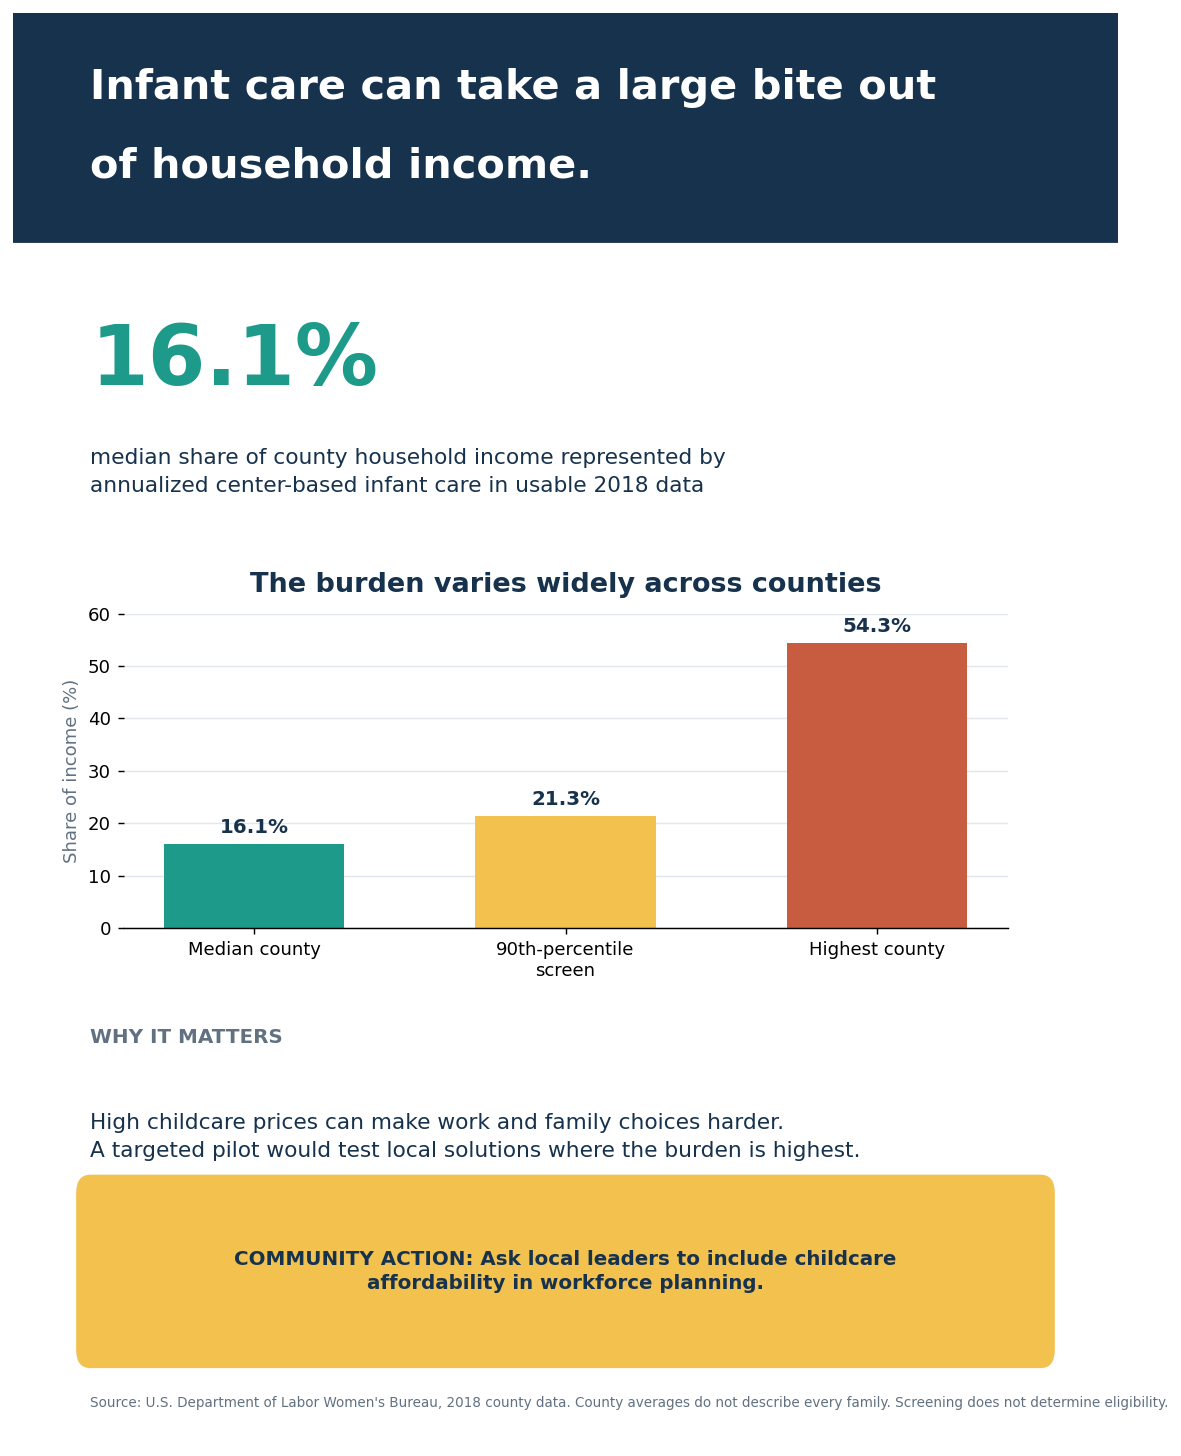

In [11]:
# Prepare the three values used in the infographic's original burden comparison chart.
infographic_values = [analysis["Burden"].median(), screening_threshold, analysis["Burden"].max()]

# Prepare plain-language labels for the three burden reference points.
infographic_labels = ["Median county", "90th-percentile\nscreen", "Highest county"]

# Create a portrait canvas that represents a one-page public infographic.
fig = plt.figure(figsize=(8.5, 11), facecolor="white")

# Add a full-page invisible axis for the infographic layout.
page = fig.add_axes([0, 0, 1, 1])

# Remove coordinate axes from the page canvas.
page.axis("off")

# Add a navy header band for strong visual hierarchy.
page.add_patch(FancyBboxPatch((0, 0.84), 1, 0.16, boxstyle="square,pad=0", facecolor=NAVY, edgecolor=NAVY))

page.text(
    0.07,
    0.94,
    "Infant care can take a large bite out",
    fontsize=23,
    weight="bold",
    color="white",
)

page.text(
    0.07,
    0.885,
    "of household income.",
    fontsize=23,
    weight="bold",
    color="white",
)

# Display the central memorable statistic in the main evidence color.
page.text(0.07, 0.74, f"{analysis['Burden'].median():.1f}%", fontsize=46, weight="bold", color=TEAL)

# Define the central statistic in simple, accurate language.
page.text(0.07, 0.665, "median share of county household income represented by\nannualized center-based infant care in usable 2018 data", fontsize=12, color=NAVY, linespacing=1.5)

# Add an original chart to the public infographic, directly addressing the instructor's earlier feedback.
chart = fig.add_axes([0.10, 0.36, 0.80, 0.22])

# Draw three bars that show the size and spread of the burden values.
bars = chart.bar(infographic_labels, infographic_values, color=[TEAL, GOLD, CORAL], width=0.58)

# Add exact percentage labels above the bars.
chart.bar_label(bars, labels=[f"{value:.1f}%" for value in infographic_values], padding=4, fontsize=11, weight="bold", color=NAVY)

# Add a takeaway title rather than a generic chart label.
chart.set_title("The burden varies widely across counties", fontsize=15, weight="bold", color=NAVY, pad=12)

# Label the vertical scale in plain language.
chart.set_ylabel("Share of income (%)", color=GRAY)

# Set a zero baseline and enough headroom for the top label.
chart.set_ylim(0, 60)

# Remove unnecessary borders and horizontal tick marks.
chart.spines[["top", "right", "left"]].set_visible(False)

# Add subtle horizontal gridlines behind the bars.
chart.grid(axis="y", color="#E1E7EB")

# Keep the gridlines behind the evidence.
chart.set_axisbelow(True)

# Add a simple explanation of why the result matters.
page.text(0.07, 0.28, "WHY IT MATTERS", fontsize=11, weight="bold", color=GRAY)

# Explain the policy connection without claiming causation.
page.text(0.07, 0.20, "High childcare prices can make work and family choices harder.\nA targeted pilot would test local solutions where the burden is highest.", fontsize=12, color=NAVY, linespacing=1.5)

# Add a prominent public action statement in gold.
# Add a larger gold community-action box.
page.add_patch(
    FancyBboxPatch(
        (0.07, 0.065),        # Left and bottom position
        0.86,                 # Box width
        0.11,                 # Box height
        boxstyle="round,pad=0.012",
        facecolor=GOLD,
        edgecolor=GOLD,
    )
)

# State the public-facing call to action.
page.text(
    0.50,
    0.12,
    "COMMUNITY ACTION: Ask local leaders to include childcare\n"
    "affordability in workforce planning.",
    fontsize=11,
    weight="bold",
    color=NAVY,
    ha="center",
    va="center",
    linespacing=1.3,
)

# Add a concise source and limitation note at the bottom of the page.
page.text(0.07, 0.025, "Source: U.S. Department of Labor Women's Bureau, 2018 county data. County averages do not describe every family. Screening does not determine eligibility.", fontsize=7.5, color=GRAY)

# Display the completed one-page infographic.
plt.show()

### Infographic Narrative

The infographic is designed for families, community partners, and other nontechnical readers. It uses one memorable statistic, one original three-bar comparison, plain-language interpretation, and one community action. Technical detail is reduced, but the year, source, denominator, and limits remain visible. The public call to action asks residents to support consideration of childcare affordability in workforce planning rather than promising a benefit that has not yet been designed or funded.

## Final Project Paper

### Summary of Analysis

The National Database of Childcare Prices was analyzed as a county-level workforce-planning resource. The project focused on 2018 because it is the most recent year in the assigned 2008-2018 dataset. Weekly childcare prices were annualized by multiplying by 52 and divided by median household income to create an affordability-burden percentage. Six care categories were reviewed, and center-based infant care became the primary screening measure because it had the highest median burden.

### Findings

Among 2,360 counties with usable 2018 center-based infant price data, the median weekly price was $153.60 and the median annualized burden was 16.1% of median household income. The project-defined 90th-percentile burden was 21.3%, and the maximum county value was 54.3%. Center toddler care had a 14.5% median burden, center preschool care had a 13.5% median burden, and the three family-care categories ranged from 11.7% to 12.5%. The geographic variation supports targeted local review instead of a uniform program. Labor force participation among women with children under age six and other workforce measures were used only as context, not as evidence that childcare prices independently cause employment outcomes.

### Assumptions and Items That Still Need Clarification

The analysis assumes 52 paid weeks of care, uses county median household income as the denominator, and treats missing prices as unavailable rather than zero. The resulting percentage is a screening measure and does not represent the exact burden experienced by every household. The 21.3% threshold is the 90th percentile of usable center-infant burden values. It is not an official affordability standard or automatic eligibility rule. Before a real pilot, leaders would need to review source imputation flags, validate newer local prices, assess provider capacity and waiting lists, identify available funding, determine whether infant care or a broader care mix should drive selection, and define measurable outcomes.

### Direction of the Story and Message

The story reframes childcare affordability as a workforce development concern rather than only a private family expense. It begins with a limited decision: approve pilot design and county screening. The evidence then shows the size and uneven distribution of the burden, explains why county conditions matter, and closes with a test-and-learn action sequence. The future pilot could evaluate one support model, such as an employer match, referral partnership, or limited subsidy, and return results before any expansion decision.

### Target Audience

The primary audience is county policymakers, workforce development board members, and local economic development leaders. They understand budgets and local labor conditions but may not know the dataset's price variables. The final materials avoid unnecessary jargon, make the requested decision visible immediately, and respond to likely resistance by proposing a focused pilot process rather than a broad permanent program. The presenter's credibility comes from translating an official public-use dataset into a transparent decision story while acknowledging what it cannot prove.

### Mediums Included and Why

Three distinct mediums address different information needs. The five-slide executive presentation guides decision makers from recommendation to evidence and action. The county screening dashboard supports analysts and policy staff who need geographic context, county comparison, active selection details, and visible data-quality notes. The one-page infographic gives families and community partners a plain-language summary with one original chart and a public-facing action statement. The mediums share the same measures and visual system but do not force every audience into the same level of detail.

### Design Decisions

Dark blue identifies policy content, teal represents affordability evidence, gold highlights the requested action, and coral is reserved for exceptional burden. Direct titles, restrained labels, common baselines, generous spacing, and repeated placement rules make the story easier to scan. Horizontal bars support accurate county and category comparisons. Metric cards serve quick executive reading, while source imputation flags remain in the analyst dashboard and a general validation requirement appears in the executive screening table. The infographic removes most technical material while preserving the formula's meaning, year, source, and limitations. These revisions also address the Milestone 2 feedback by including original graphs in both the executive presentation and infographic.

### Ethical Considerations

The data were obtained ethically from the U.S. Department of Labor Women's Bureau and reviewed against the dataset documentation. The childcare prices originated from state market rate surveys conducted by lead agencies under Child Care and Development Fund requirements. This project does not evaluate regulatory compliance, but those requirements provide context for how the underlying price information was collected. Transformations were limited to selecting 2018 records, annualizing weekly prices, and calculating burden percentages; source price values were not altered. Missing observations were excluded only from the affected measure and were never converted to zero. Some price estimates are imputed, so source flags are retained and local verification is required before funding decisions. County averages may hide variation among families and providers, and historical data may not reflect present market conditions. The public-use dataset contains aggregate county information rather than protected personal records, so no individual privacy regulation appears to control this analysis. However, users must still avoid stigmatizing counties, overstating causation, or turning a percentile screen into an entitlement rule. Mitigation includes clear labels, disclosed formulas and filters, visible limitations, local review, equity assessment, and evaluation before expansion.

### Lessons Learned

The strongest lesson was that a persuasive visual story requires subtraction. A large dataset can support many comparisons, but each medium works best when it answers one audience question. I most enjoyed translating the same verified evidence into three different communication experiences. Next time, I would validate percentile terminology and imputation definitions earlier, create a formal data dictionary before designing visuals, and test the dashboard and infographic with representative users. I would also add newer local price, provider-capacity, and employer data so a future recommendation reflects current conditions rather than relying only on the historical endpoint of the assigned dataset.

## Conclusion

This final project demonstrates how data presentation choices shape whether analysis becomes useful for a decision. The executive presentation makes the pilot request clear, the dashboard preserves depth and uncertainty for analysts, and the infographic translates the issue for the public. Across all three formats, the evidence supports targeted local review while the visible limitations prevent the story from becoming stronger than the data.

The project also reinforces a central theme of data storytelling: the goal is not to display every possible result. The goal is to select credible evidence, organize it around an audience's decision, and use design intentionally. The recommended next step is to approve pilot design and county screening, verify current local conditions, and return with a bounded proposal that includes measurable cost, participation, retention, and equity outcomes.

## References

U.S. Department of Labor, Women’s Bureau. (2020). *National Database of Childcare Prices: Final report*. https://www.dol.gov/sites/dolgov/files/WB/National-Database-of-Childcare-Prices-Technical-Report.pdf

U.S. Department of Labor, Women's Bureau. (2024). *National Database of Childcare Prices*. https://www.dol.gov/agencies/wb/topics/featured-childcare